# E-Commerce Project using Python
This dataset consists of orders made in different countries from December 2010 to December 2011. The company ixs a UK-based online retailer that mainly sells unique all-occasion gifts. Many of its customers are wholesalers. 

## Data Dictionary
| Variable    | Explanation                                                                                                                       |
|-------------|-----------------------------------------------------------------------------------------------------------------------------------|
| InvoiceNo   | A 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c' it indicates a cancellation. |
| StockCode   | A 5-digit integral number uniquely assigned to each distinct product.                                                             |
| Description | Product (item) name                                                                                                               |
| Quantity    | The quantities of each product (item) per transaction                                                                             |
| InvoiceDate | The day and time when each transaction was generated                                                                              |
| UnitPrice   | Product price per unit in sterling (pound)                                                                                        |
| CustomerID  | A 5-digit integral number uniquely assigned to each customer                                                                      |
| Country     | The name of the country where each customer resides                                                                               |

[Source](https://archive.ics.uci.edu/ml/datasets/online+retail#)  of dataset.

**Citation:** Daqing Chen, Sai Liang Sain, and Kun Guo, Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining, Journal of Database Marketing and Customer Strategy Management, Vol. 19, No. 3, pp. 197-208, 2012 (Published online before print: 27 August 2012. doi: 10.1057/dbm.2012.17).

In [19]:
import pandas as pd
retail = pd.read_csv(r'/Users/admin/Downloads/online_retail.csv')

## **Executive Summary**

The analysis reveals a highly seasonal, volume-driven wholesale business where revenue is heavily concentrated among a small segment of high-value, repeat domestic customers. While the company maintains a global footprint, the vital engine of growth remains the UK market, driven by reliable, high-demand "hit" products rather than premium pricing. To maximize profitability and operational efficiency, strategic efforts must pivot from broad customer acquisition to maximizing Customer Lifetime Value (CLV) through VIP retention, targeted cross-selling, and inventory optimization.

### **Core Findings**
- **Revenue Concentratio**n: Revenue is highly concentrated, with the top 10% of customers generating 61% of total sales. This cohort represents the core financial stability of the business, outperforming the second-tier decile by a factor of 4.5x.
- **Retention-Driven Growth**: Monthly revenue trends demonstrate a massive disparity between first-time and repeat customers. While repeat customers drive significant volume and show strong seasonal growth, first-time customer revenue remains flat and negligible.
- **Operational Leakage**: Return rate analysis identified that "financial leaks" are partially driven by operational overhead (e.g., Amazon fees, samples) alongside specific products where customer expectations fail to align with descriptions.
- **Engagement Disparity**: While the average customer places 5 orders per year, our most loyal "Power Users" place up to 209 orders, highlighting a significant "Loyalty Gap."

### **Strategic Roadmap**
To scale effectively, the business must pivot from passive observation to precision targeting:
- **VIP Retention**: Implement a dedicated loyalty program for top-tier "Power Users" to protect the 61% of revenue they provide.
- **Conversion Optimization:** The stagnant performance of first-time customers indicates an untapped opportunity. We must analyze the "Gateway Products"—the items that successfully convert first-time buyers into repeat shoppers—and promote these as hooks in acquisition campaigns.
- **Data-Driven Quality Control**: Prioritize a content audit (photography and descriptions) for products with the highest return rates to reduce financial leakage and improve customer satisfaction.
- **Cohort Modeling**: Develop "Lookalike Models" based on the demographic and acquisition traits of our top 10% to shift marketing spend toward channels that acquire high-lifetime-value (LTV) customers.
  
### **Conclusion**
The company’s growth is currently built on the backs of a narrow, loyal base. Long-term sustainability depends on our ability to bridge the gap between casual shoppers and Power Users, while simultaneously optimizing the acquisition funnel to ensure new traffic converts into long-term, high-value cohorts.

_*** More in Strategic Recommendations & Business Impact Section at the end._

# **1. Data Cleaning & Preparation**

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
# Check how many missing values exist per column
print(retail.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [22]:
# Fill missing Customer IDs with 'Unknown'
retail['CustomerID'] = retail['CustomerID'].fillna('Unknown')

# Drop rows where the product description is completely missing
retail = retail.dropna(subset=['Description'])

# Convert the text date column into datetime object
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'], format='%m/%d/%y %H:%M')

# Create separate columns for easy time-based grouping later
retail['YearMonth'] = retail['InvoiceDate'].dt.to_period('M')
retail['Quarter'] = retail['InvoiceDate'].dt.to_period('Q')
retail['Week'] = retail['InvoiceDate'].dt.to_period('W')

_***E-commerce data often contains cancelled orders, testing records, or adjustments that show up as negative quantities or zero prices. In this specific dataset, return transactions start with a "C" in the InvoiceNo._

In [23]:
# Identify returned orders (starts with 'C' in InvoiceNo)
retail['Is_Return'] = retail['InvoiceNo'].astype(str).str.startswith('C')

# Keep only rows where Quantity and UnitPrice are greater than zero for standard sales analysis
df_sales = retail[(retail['Quantity'] > 0) & (retail['UnitPrice'] > 0) & (retail['Is_Return'] == False)].copy()

# Keep returns in a separate dataframe 
df_returns = retail[retail['Is_Return'] == True].copy()

# Creat Revenue column
df_sales['Revenue'] = df_sales['Quantity'] * df_sales['UnitPrice']

# **2. Business Analytics**

## **Part I: Sales & Revenue Trends**

### **Q1: What are the weekly, monthly, and quarterly profit and revenue trends for UK customers?**

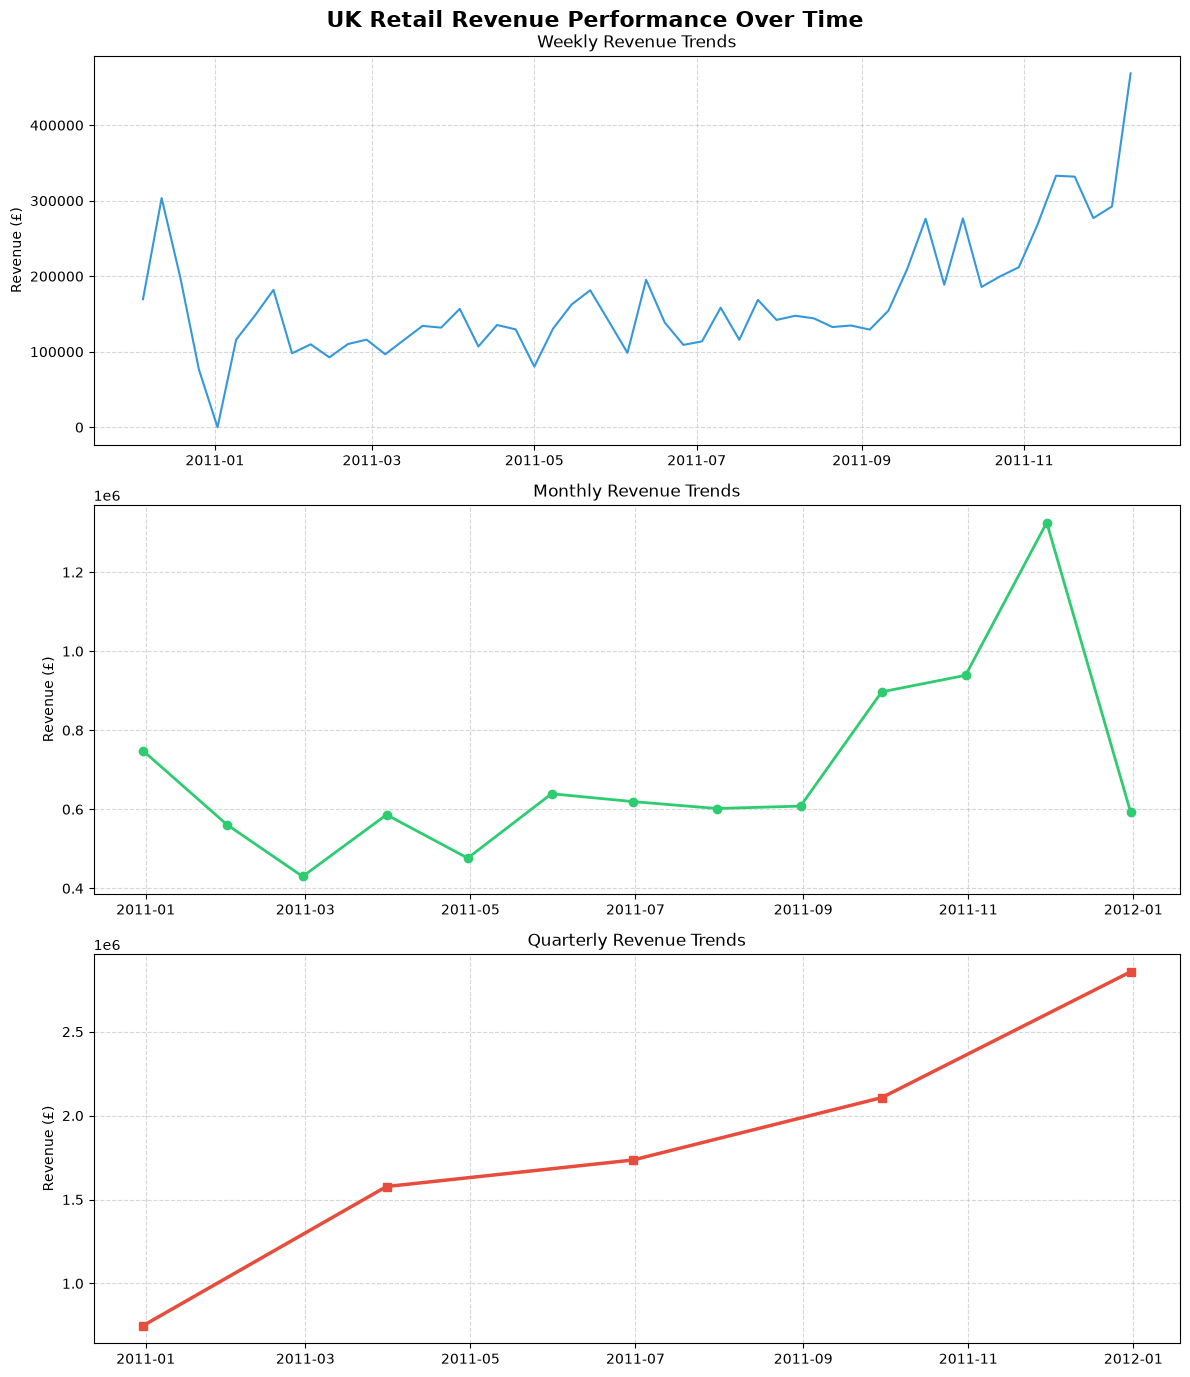

In [24]:
# 1. Subset UK customers from the df_sales
df_uk = df_sales[df_sales['Country'] == 'United Kingdom']

# 2. Set InvoiceDate is set as the index for time-based tracking
df_time = df_uk.set_index('InvoiceDate')

weekly_revenue = df_time['Revenue'].resample('W').sum()
monthly_revenue = df_time['Revenue'].resample('ME').sum()
quarterly_revenue = df_time['Revenue'].resample('QE').sum()

# 3. Create the all-in-one stacked layout
fig, axes = plt.subplots(3, 1, figsize=(12, 14), sharex=False)
fig.suptitle('UK Retail Revenue Performance Over Time', fontsize=16, fontweight='bold')

# Panel 1: Weekly 
axes[0].plot(weekly_revenue.index, weekly_revenue.values, color='#3498db', linewidth=1.5)
axes[0].set_title('Weekly Revenue Trends', fontsize=12)
axes[0].set_ylabel('Revenue (£)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Monthly 
axes[1].plot(monthly_revenue.index, monthly_revenue.values, color='#2ecc71', marker='o', linewidth=2)
axes[1].set_title('Monthly Revenue Trends', fontsize=12)
axes[1].set_ylabel('Revenue (£)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: Quarterly 
axes[2].plot(quarterly_revenue.index, quarterly_revenue.values, color='#e74c3c', marker='s', linewidth=2.5)
axes[2].set_title('Quarterly Revenue Trends', fontsize=12)
axes[2].set_ylabel('Revenue (£)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Q1 - Key Takeaways

The business follows a highly seasonal sales cycle, heavily dependent on Q4 holiday volume.

**Insights:**
- **The Peak**: Revenue steadily climbed throughout the year, exploding into a massive peak during the Q4 Holiday Season (October–December). This indicates that wholesale buyers ramp up their purchasing volumes to prepare for winter gift-giving demand.
- **The Trough**: Conversely, the lowest revenue period occurred in March. This represents a post-winter slump where transaction volumes bottomed out before stabilizing in the spring.

### **Q2: How do order sizes (Quantity) and order values compare between UK customers and international customers?**

/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/2176830394.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Market', y='Median Units', data=summary_data, ax=axes[0], palette='Blues_d')
/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/2176830394.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Market', y='Median Revenue', data=summary_data, ax=axes[1], palette='Greens_d')


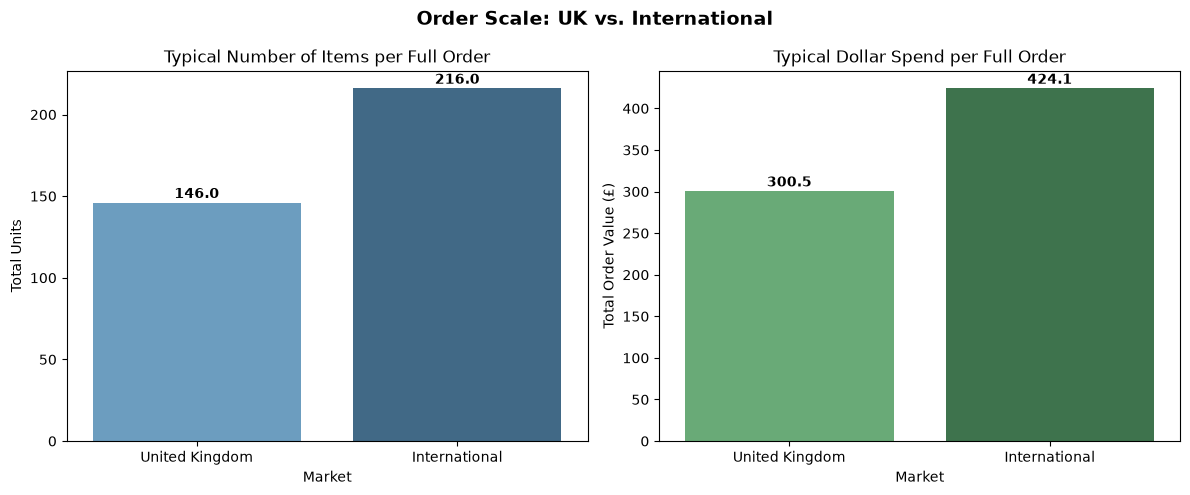

In [25]:
# 1. Calculate total items and total revenue spent per invoice
uk_orders = df_sales[df_sales['Country'] == 'United Kingdom'].groupby('InvoiceNo').agg({
    'Quantity': 'sum',
    'Revenue': 'sum'
})

int_orders = df_sales[df_sales['Country'] != 'United Kingdom'].groupby('InvoiceNo').agg({
    'Quantity': 'sum',
    'Revenue': 'sum'
})

# 2. Combine the MEDIAN scores 
summary_data = pd.DataFrame({
    'Market': ['United Kingdom', 'International'],
    'Median Units': [uk_orders['Quantity'].median(), int_orders['Quantity'].median()],
    'Median Revenue': [uk_orders['Revenue'].median(), int_orders['Revenue'].median()]
})

# 3. Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Order Scale: UK vs. International', fontsize=14, fontweight='bold')

# Chart 1: Median Units
sns.barplot(x='Market', y='Median Units', data=summary_data, ax=axes[0], palette='Blues_d')
axes[0].set_title('Typical Number of Items per Full Order')
axes[0].set_ylabel('Total Units')

# Chart 2: Median Revenue
sns.barplot(x='Market', y='Median Revenue', data=summary_data, ax=axes[1], palette='Greens_d')
axes[1].set_title('Typical Dollar Spend per Full Order')
axes[1].set_ylabel('Total Order Value (£)')

# Add value labels to the bars
for ax in axes:
 for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontweight='bold', xytext=(0, 1), textcoords='offset points')
plt.tight_layout()
plt.show()

#### Q2 - Key Takeaways

While international transactions are larger on an individual wholesale scale, domestic UK customers represent the vital engine of total company sales volume.

**Insights:**
- A deep dive into full transaction order sizes reveals that customers within the United Kingdom contribute the vast majority of business volume.
- Full orders originating from the UK account for a dominant 67% of the total order quantity and drive 71% of total company revenue.

### **Q3: Outside of the UK, which top 5 countries generate the highest total revenue?**

/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/620673462.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Country', y='Revenue', data=int_rank_revenue, palette='Greens', ax=ax)


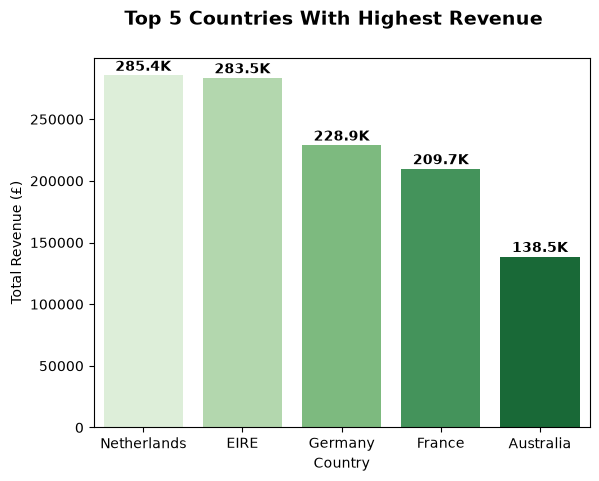

In [26]:
# Rank countries by revenue
int_rank_revenue = df_sales[df_sales['Country'] != 'United Kingdom'].groupby('Country')['Revenue'].sum().sort_values(ascending=False)
int_rank_revenue = int_rank_revenue.head(5)

# Convert Series to DataFrame and reset index
int_rank_revenue = int_rank_revenue.reset_index()

fig, ax = plt.subplots()
fig.suptitle('Top 5 Countries With Highest Revenue', fontsize=14, fontweight='bold')
sns.barplot(x='Country', y='Revenue', data=int_rank_revenue, palette='Greens', ax=ax)
ax.set_ylabel('Total Revenue (£)')

# Format large numbers
def format_label(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.1f}M"
    elif value >= 1_000:
        return f"{value / 1_000:.1f}K"
    else:
        return f"{value:.0f}"

# Revised annotation loop
for p in ax.patches:
    height = p.get_height()
    ax.annotate(format_label(height), 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', 
                fontweight='bold', 
                xytext=(0, 1), 
                textcoords='offset points')
plt.show()

#### Q4 - Key Takeaways

International revenue is heavily concentrated in a small group of European neighbors and Australia, with a steep drop-off between the top-tier and mid-tier global markets.

**Insights:**

- **The Top Markets**: Outside of the United Kingdom, the primary international revenue engines for the business are the Netherlands, EIRE (Ireland), Germany, and Australia.

- **The Top 1 vs. Top 2 Battle**: The revenue differences between Rank 1 (Netherlands) and Rank 2 (EIRE) are relatively slight, showing that both regions share a similarly high demand for wholesale gift items.

- **The Drop-Off**: However, the data reveals a steep distribution curve. The highest-performing international country (Netherlands) generates over double the total revenue compared to the fifth highest-performing country.

## **PART II: Product & Inventory Performance**

### **Q4: Which top 10 products drive the highest total revenue, and which have the highest total quantity sold?**

/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/4075389595.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Revenue', y='Description', data=top_products_revenue, ax=axes[0], palette='Blues_d')
/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/4075389595.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Quantity', y='Description', data=top_products_quantity, ax=axes[1], palette='Greens_d')


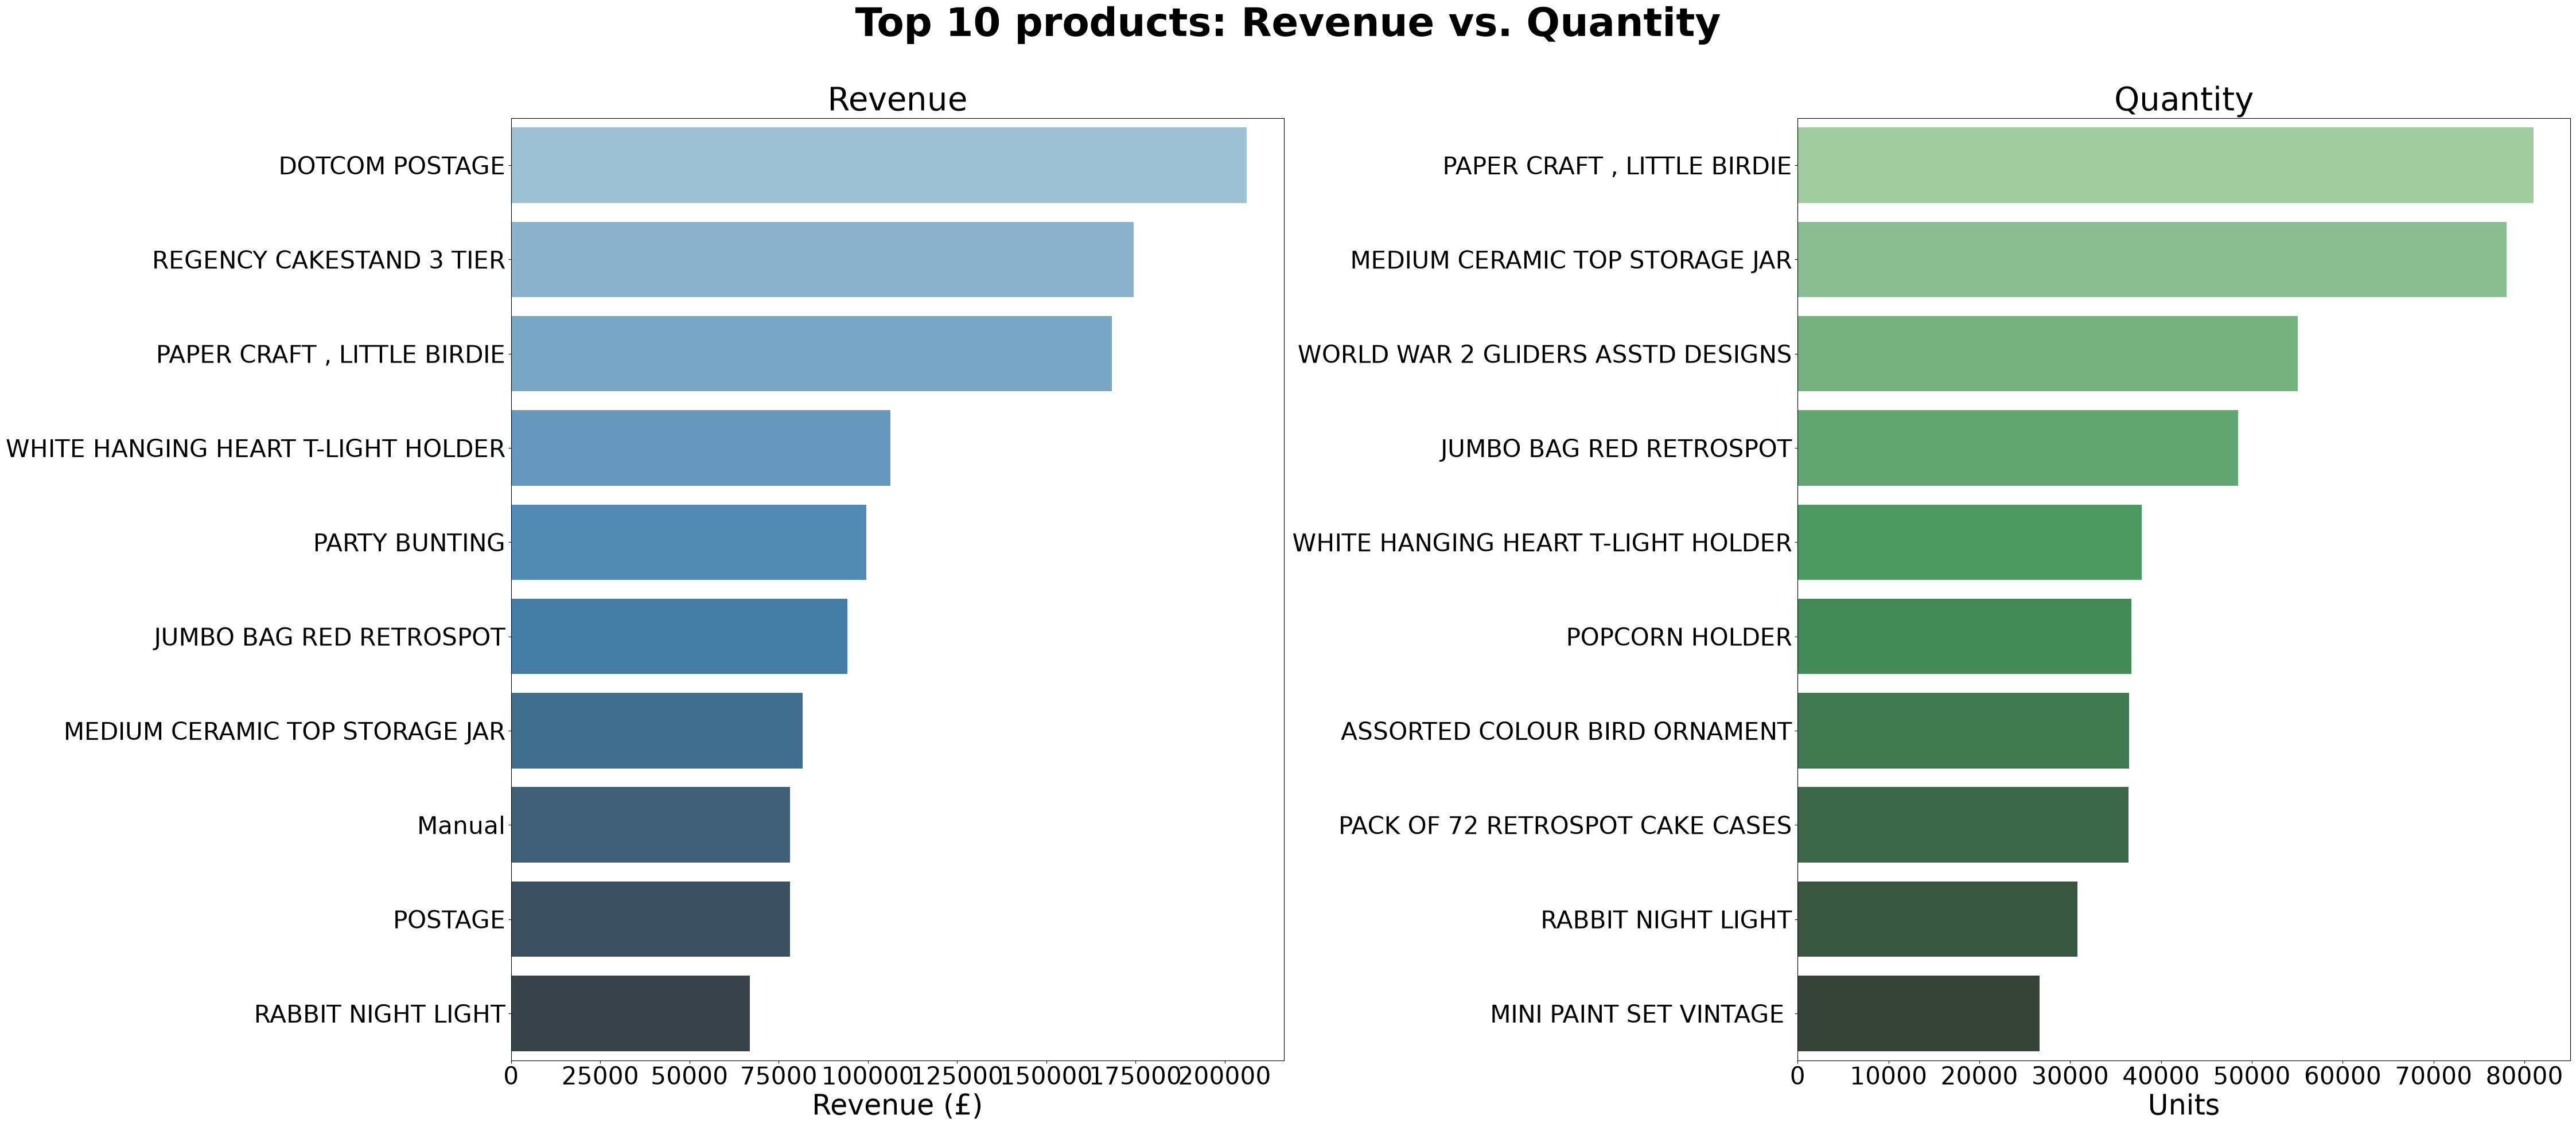

,Description,Revenue_x,Quantity_x,Revenue_y,Quantity_y
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,168469.60,80995
1,WHITE HANGING HEART T-LIGHT HOLDER,106292.77,37891,106292.77,37891
2,JUMBO BAG RED RETROSPOT,94340.05,48474,94340.05,48474
3,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,81700.92,78033
4,RABBIT NIGHT LIGHT,66964.99,30788,66964.99,30788


In [28]:
# 1. Find top products
top_products = df_sales.groupby('Description').agg({'Revenue':'sum', 
                                                    'Quantity':'sum'})
top_products = top_products.reset_index()
top_products_revenue = top_products.sort_values('Revenue', ascending = False).head(10)
top_products_quantity = top_products.sort_values('Quantity',ascending = False).head(10)

# 2. Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(45, 20))
fig.suptitle('Top 10 products: Revenue vs. Quantity', fontsize=50, fontweight='bold')

# Chart 1: Top 10 products by Revenue
sns.barplot(x='Revenue', y='Description', data=top_products_revenue, ax=axes[0], palette='Blues_d')
axes[0].set_title('Revenue', fontsize=40)
axes[0].set_xlabel('Revenue (£)', fontsize=35)
axes[0].set_ylabel('', fontsize=40) 
axes[0].tick_params(axis='x', labelsize=30)
axes[0].tick_params(axis='y', labelsize=30)

# Chart 2: Top 10 products by Quantity
sns.barplot(x='Quantity', y='Description', data=top_products_quantity, ax=axes[1], palette='Greens_d')
axes[1].set_title('Quantity', fontsize=40)
axes[1].set_xlabel('Units', fontsize=35)
axes[1].set_ylabel('', fontsize=40)  
axes[1].tick_params(axis='x', labelsize=30)
axes[1].tick_params(axis='y', labelsize=30)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Products with highest revenue and quantity
top_both = pd.merge(top_products_revenue, top_products_quantity, on ='Description')
top_both

#### Q4 - Key Takeaways

Top product revenue is primarily volume-driven rather than premium-priced.

Out of thousands of catalog items, five products successfully rank in both the Top 10 by Total Revenue and the Top 10 by Quantity Sold.

**The High-Volume MVPs:**
- PAPER CRAFT , LITTLE BIRDIE
- WHITE HANGING HEART T-LIGHT HOLDER
- JUMBO BAG RED RETROSPOT
- MEDIUM CERAMIC TOP STORAGE JAR
- RABBIT NIGHT LIGHT

These specific products represent the company's core wholesale "hits." They are highly predictable, high-demand items that retail buyers rely on to stock their own shelves, making them critical for our inventory health and supply chain focus.

### **Q5: Which specific products have the highest cancellation or return rates?**

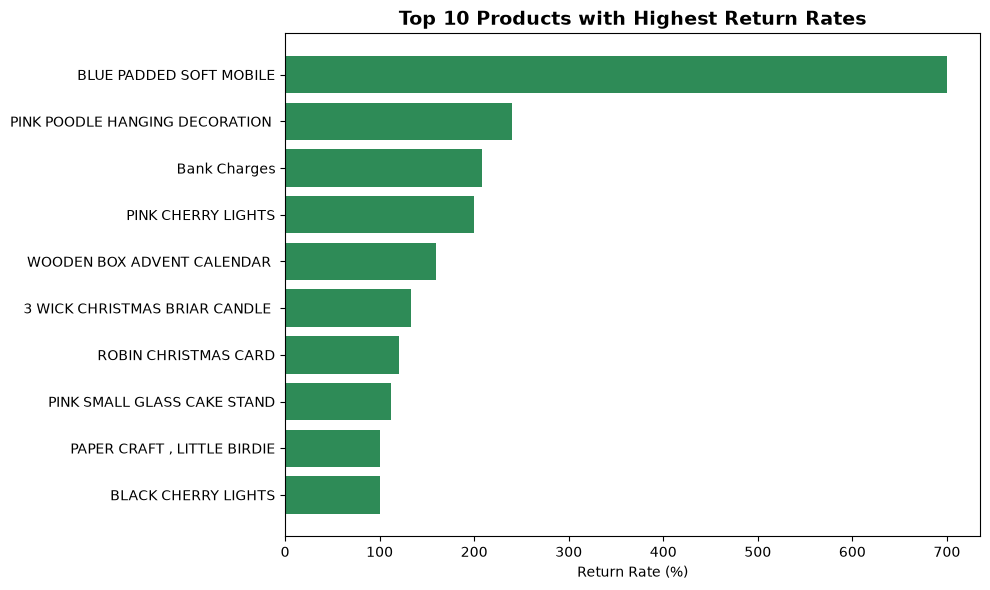

In [29]:
# Get the list of returned products
return_list = df_returns['Description'].unique()
operational_products = ['AMAZON FEE', 'MANUAL', 'Test', 'Discount', 'SAMPLES']
return_list_operation_exl = return_list[~np.isin(return_list, operational_products)]

# Get the total quantity of products that were returned 
total_quantity_returns = df_sales[df_sales['Description'].isin(return_list_operation_exl)].groupby('Description')['Quantity'].sum()

# Get the return quantity 
return_quantity = df_returns.groupby('Description')['Quantity'].sum()

# Reset index to make 'Description' a column for merging
total_quantity_returns = total_quantity_returns.reset_index()
return_quantity = return_quantity.reset_index()

# Calculate the return rate
return_products_final = pd.merge(
    total_quantity_returns, 
    return_quantity, 
    on='Description',  
    suffixes=('_sold', '_returned')
)

return_products_final['Return_rate'] = round(
    np.abs(return_products_final['Quantity_returned']) / 
    return_products_final['Quantity_sold'] * 100, 2
)

top_return_products= return_products_final.sort_values('Return_rate', ascending = False).head(10)

# Plot the top 10 products
plt.figure(figsize=(10, 6))
plt.barh(top_return_products['Description'], top_return_products['Return_rate'], color='seagreen')
plt.xlabel('Return Rate (%)')
plt.title('Top 10 Products with Highest Return Rates', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### Q5 - Key Takeaways

Filtering out non-product ledger entries (such as Amazon fee, Samples, Discounts) reveals that while operational costs (such as "Amazon Fees" and "Samples") account for significant financial leakage, a distinct subset of physical products exhibits disproportionately high return rates. Further analysis suggests these return seasons correlate with items where product photography or descriptions may be failing to align with customer expectations.

### **Q6: Which products are frequently bought together in the same transaction?**

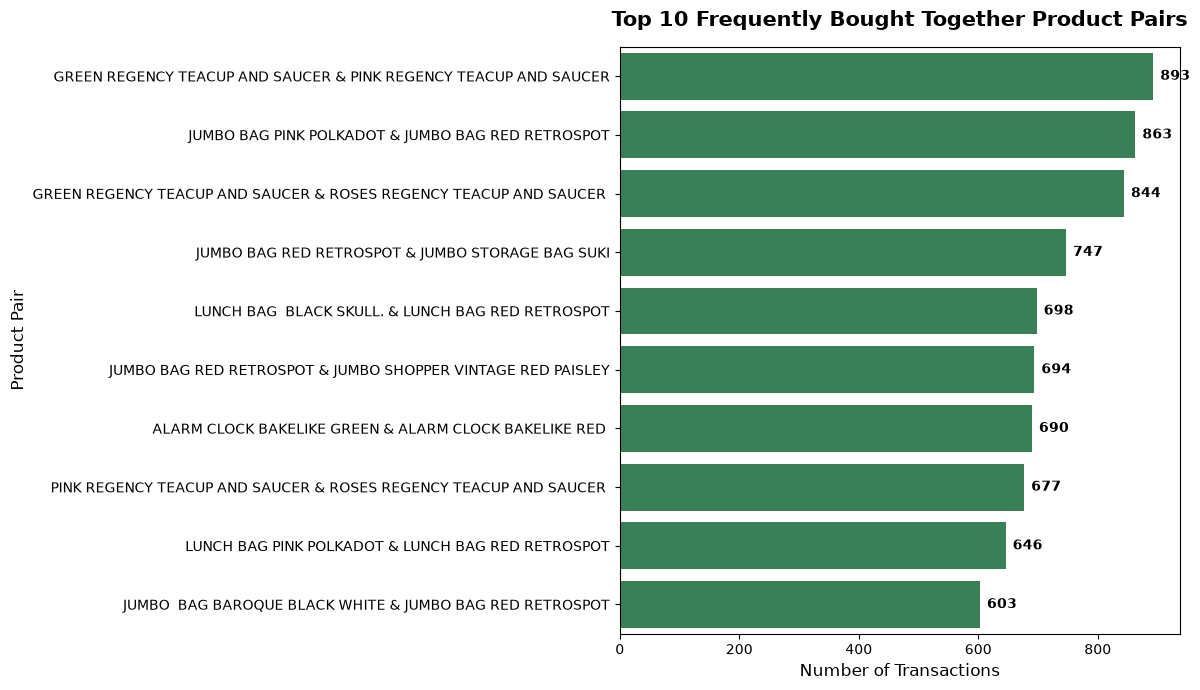

In [30]:
from itertools import combinations
from collections import Counter

# 1. Filter for orders that have more than 1 item
df_multi_items = df_sales.groupby('InvoiceNo').filter(lambda x: len(x) > 1)

# 2. Extract unique lists of products per invoice
grouped_products = df_multi_items.groupby('InvoiceNo')['Description'].apply(list)

# 3. Find all combinations of 2 products for each invoice and count them
pair_counts = Counter()

for products in grouped_products:
    # Sort the items to ensure (A, B) is treated the same as (B, A)
    pair_counts.update(combinations(sorted(products), 2))

# 4. Convert to a DataFrame
top_pairs = pd.DataFrame.from_dict(pair_counts, orient='index', columns=['Frequency'])
top_pairs = top_pairs.sort_values(by='Frequency', ascending=False).head(10)

# Resetting index to get pair names as a column
plot_data = top_pairs.reset_index().rename(columns={'index': 'Product Pair'})
plot_data['Product Pair'] = plot_data['Product Pair'].apply(lambda x: f"{x[0]} & {x[1]}")

plt.figure(figsize=(12, 7))

ax = sns.barplot(x='Frequency', y='Product Pair', data=plot_data, color='seagreen')

plt.title('Top 10 Frequently Bought Together Product Pairs', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Number of Transactions', fontsize=12)
plt.ylabel('Product Pair', fontsize=12)

# Add data labels
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", 
                (p.get_width(), p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

#### Q6 - Key Takeaways

Analysis reveals that customers frequently purchase complementary color variations of the same product line in a single transaction. 

**Key Findings:** The pair of 'GREEN REGENCY TEACUP AND SAUCER' and 'PINK REGENCY TEACUP AND SAUCER' emerged as one of the most frequently bought combinations. The 'Jumbo Bag' product line drives significant pairing volume, accounting for 4 of the top 10 most frequent pairings. 

**Business Recommendation:** These pairings should be leveraged for website "Frequently Bought Together" bundles, targeted email marketing campaigns, or physical warehouse storage optimization (placing frequently paired items in the same aisle).

## PART III: Customer Behavior Analysis

### **Q7: Who are our top 10% highest-spending customers, and what percentage of total revenue do they represent?**

Top 10% highest-spending customers generate 61.0% of total revenue.


/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/2416083642.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segment_revenue = customers_rank.groupby('Quantiles')['Revenue'].sum()


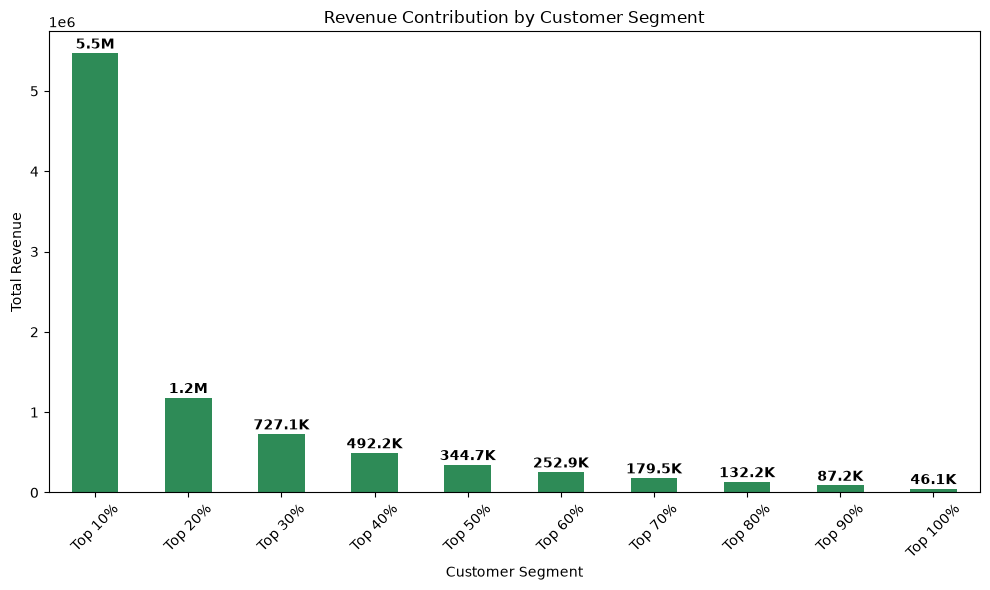

In [31]:
# Group by CustomerID
customers_rank = df_sales[df_sales['CustomerID']!='Unknown'].groupby('CustomerID')['Revenue'].sum()
customers_rank = customers_rank.reset_index()

labels = [f"Top {i}%" for i in range(100, 0, -10)]

customers_rank['Quantiles'] = pd.qcut(customers_rank['Revenue'], q=10, labels=labels)

top_10_revenue = round(customers_rank[customers_rank['Quantiles']=='Top 10%']['Revenue'].sum(),2)

pct = round((top_10_revenue/customers_rank['Revenue'].sum() *100),0)

print(f'Top 10% highest-spending customers generate {pct}% of total revenue.')

# Group by the Quantiles you created
segment_revenue = customers_rank.groupby('Quantiles')['Revenue'].sum()

# Plotting
plt.figure(figsize=(10, 6))
ax = segment_revenue.plot(kind='bar', color='seagreen')

plt.title('Revenue Contribution by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Revenue')
plt.gca().invert_xaxis()
plt.xticks(rotation=45)

# Format large numbers
def format_label(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.1f}M"
    elif value >= 1_000:
        return f"{value / 1_000:.1f}K"
    else:
        return f"{value:.0f}"

# Annotation loop
for p in ax.patches:
    height = p.get_height()
    ax.annotate(format_label(height), 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', 
                fontweight='bold', 
                xytext=(0, 1), 
                textcoords='offset points')
                
plt.tight_layout()
plt.show()

#### Q7 - Key Takeaways

Customer revenue is highly concentrated, with the top 10% of spenders driving a significant majority of total sales.

**Insights:** The data confirms that this top tier accounts for 61% of total revenue, a figure more than 4.5 times higher than the second-highest decile.

**Business Recommendations:** 

- **VIP Retention Program**:Personalized rewards, early access to new collections, and dedicated customer service for top 10% group are essential to prevent churn in this high-value segment.
- **High-Value Lookalike Modeling**: Marketing efforts should focus on "Lookalike Audiences"—using the purchase history of this 10% to target prospective customers who share similar traits.
- **Second-Tier Upsell**: With such a large gap (4.5x) between the first and second tier, there is a clear opportunity to identify "rising stars" in the second decile and provide targeted "upsell" campaigns to bridge the gap toward the top-tier status.

### **Q8: How often do unique customers return to buy again within this 12-month period?**

/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/43535842.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_10['CustomerID'] = top_10['CustomerID'].astype(int).astype(str)


One customer purchase an average of 5 orders.


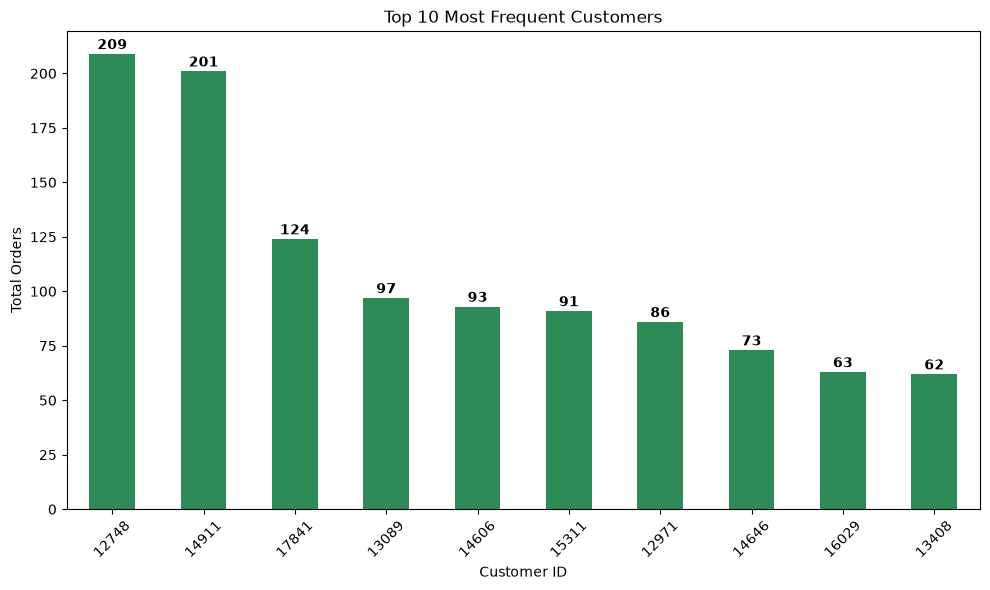

In [32]:
# Count InvoiceNo entries per CustomerID
invoice_per_customer = (
    df_sales[df_sales['CustomerID'] != 'Unknown']
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .reset_index(name='Count')
    .sort_values(by='Count', ascending=False)
)

top_10 = invoice_per_customer.head(10)

top_10['CustomerID'] = top_10['CustomerID'].astype(int).astype(str)

# Calculate average orders per a customer
total_orders = df_sales['InvoiceNo'].nunique()
total_unique_customers = df_sales['CustomerID'].nunique()

print(f'One customer purchase an average of {round(total_orders/total_unique_customers)} orders.')

# Plotting
plt.figure(figsize=(10, 6))
ax = top_10.plot(
    kind='bar', 
    x='CustomerID', 
    y='Count', 
    color='seagreen', 
    legend=False, 
    ax=plt.gca())
    
plt.title('Top 10 Most Frequent Customers')
plt.xlabel('Customer ID')
plt.ylabel('Total Orders')
plt.xticks(rotation=45)
    
# Annotation loop
for p in ax.patches:
    ax.annotate(f"{p.get_height():}", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', 
                fontweight='bold', 
                xytext=(0, 1), 
                textcoords='offset points')

plt.tight_layout()
plt.show()


#### Q8 - Key Takeaways

While the average customer frequency is 5 orders per year, our top-tier customers significantly outperform this benchmark with up to 209 orders.

**Insights:** The large disparity between the 5-order average and the 209-order benchmark suggests that our loyalty isn't evenly distributed. We have a clear opportunity to increase the Customer Lifetime Value (CLV) by implementing tiered re-engagement campaigns that target "casual" shoppers (those with 1–3 orders) and nudge them toward the behavior of our more frequent buyers.

Further analysis should be conducted to build 'Lookalike Models' based on these most frequent customers'traits, including:
- Identify which marketing or referral channels brought these users to the store, then shift marketing spend toward the channels that yield 'high-lifetime-value' (LTV) customers rather than just 'high-volume' traffic. 
- Analyze the first product purchased by these top-tier customers to promote these products as a primary hook for new traffic.


### **Q9: How much revenue comes from first-time buyers versus repeat customers month-over-month?**

/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/2882015563.py:22: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  first_time_customer_monthly_revenue = first_time_customers['Revenue'].resample('M').sum()
/var/folders/2n/26zsw4gx32b33r0jpd48s61h0000gn/T/ipykernel_8668/2882015563.py:23: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  repeat_customer_monthly_revenue = repeat_customers['Revenue'].resample('M').sum()


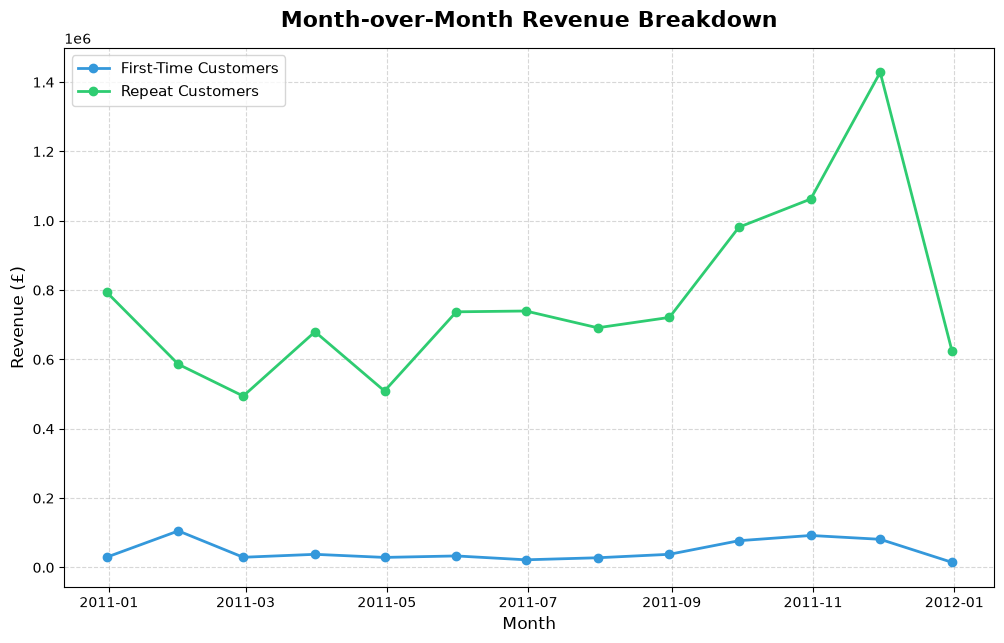

In [33]:
# Group by customer and count UNIQUE invoices, dropping missing IDs
invoice_per_customer = df_sales.dropna(subset=['CustomerID']).groupby('CustomerID')['InvoiceNo'].nunique()

## For First time customers
# Extract IDs of customers who have exactly 1 unique invoice total
first_time_customerID = invoice_per_customer[invoice_per_customer == 1].index

# Pull their original transactions from the sales sheet
first_time_customers = df_sales[df_sales['CustomerID'].isin(first_time_customerID)]

## For Repeat customers (same steps as in First-time customers)
repeat_customerID =  invoice_per_customer[invoice_per_customer > 1].index

repeat_customers = df_sales[df_sales['CustomerID'].isin(repeat_customerID)]

# Plotting

# Set 'InvoiceDate' as index for resampling
first_time_customers = first_time_customers.set_index('InvoiceDate')
repeat_customers = repeat_customers.set_index('InvoiceDate')

first_time_customer_monthly_revenue = first_time_customers['Revenue'].resample('M').sum()
repeat_customer_monthly_revenue = repeat_customers['Revenue'].resample('M').sum()

fig, ax = plt.subplots(figsize=(12, 7))

# Panel 1: First-time customers
ax.plot(
    first_time_customer_monthly_revenue.index, 
    first_time_customer_monthly_revenue.values, 
    color='#3498db',
    marker='o',
    linewidth=2, 
    label='First-Time Customers'
)

# Panel 2: Repeat customers
ax.plot(
    repeat_customer_monthly_revenue.index, 
    repeat_customer_monthly_revenue.values, 
    color='#2ecc71', 
    marker='o', 
    linewidth=2, 
    label='Repeat Customers'    
)

ax.set_title('Month-over-Month Revenue Breakdown', fontsize=16, fontweight='bold', pad=15)
ax.set_ylabel('Revenue (£)', fontsize=12)
ax.set_xlabel('Month', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=11, loc='upper left')

plt.show()


#### Q9 - Key Takeaways

Revenue performance is overwhelmingly driven by the 'Repeat Customer' cohort, which consistently generates significantly higher monthly volume than first-time acquisitions. While repeat customer revenue shows a strong upward trend throughout the year—peaking toward the end of 2011—first-time customer contributions remain relatively flat and negligible by comparison.

# 3. Strategic Recommendations & Business Impact

### 3.1. Capitalize on Customer Concentration & Loyalty

Customer revenue is highly skewed, with the top 10% of spenders generating 61% of total revenue—an output 4.5 times higher than the second-highest tier. Additionally, repeat customers overwhelmingly drive month-over-month volume, while first-time buyer contributions remain relatively flat and negligible.
- Launch a VIP Retention Program: Establish personalized rewards, early access to collections, and dedicated service for the top 10% of customers to prevent churn in this critical segment.
- Implement Tiered Upselling: Address the disparity between the 5-order average and the 209-order top-tier benchmark by deploying re-engagement campaigns that target casual shoppers (1–3 orders) and second-tier customers.
- Deploy Lookalike Modeling: Shift marketing spend away from raw volume traffic and toward channels that acquire high-lifetime-value (LTV) users, using the traits and initial purchase behaviors of the most frequent buyers.


### 3.2. Optimize Inventory & Merchandising

Top product performance is anchored by volume. Out of thousands of catalog items, a core group of five products—including the Jumbo Bag Red Retrospot and Rabbit Night Light—rank in the Top 10 for both revenue and quantity sold. Furthermore, basket analysis proves customers frequently buy complementary items, such as color variations of the Regency Teacup and Saucer.
- Leverage Product Bundling: Utilize frequently paired items to create "Frequently Bought Together" bundles on the website and targeted email campaigns.
- Optimize Warehouse Operations: Physically place frequently paired items in the same warehouse aisles to speed up order fulfillment.
- Investigate Financial Leakage: Audit product photography and descriptions for the distinct subset of physical items exhibiting disproportionately high return rates to ensure they meet customer expectations.

### 3.3. Streamline Geographic & Seasonal Focus

The business is highly reliant on the Q4 holiday season (October–December), representing a massive peak in wholesale purchasing before bottoming out in March. Geographically, UK customers represent 67% of total order quantity and 71% of total revenue.
- Protect the Domestic Engine: Prioritize UK-focused marketing and logistics to support the region driving the vast majority of business volume.
- Target International Spend: Concentrate international efforts on the proven top-tier markets—the Netherlands, EIRE, Germany, and Australia—as data shows a steep drop-off in revenue beyond these regions.
- Align Supply Chain with Seasonality: Ensure the supply chain for the five core MVP products is fully secured well ahead of the Q4 surge to capture peak winter gift-giving demand.

# END OF THE REPORT! THANK YOU 